# Stellarator design for people who train models

A stellarator uses a twisted magnetic field to confine a plasma. Changing its shape changes how the field lines wind and how particles drift. The design problem is to find shapes with useful properties, subject to physics and engineering constraints.

Here is a small problem you can run and modify: **six shape parameters, a physics solver, and a few scalar outputs.** We approach it twice: learn from a database, then optimize through the solver's derivatives. No plasma-physics background is assumed.

The opportunity resembles what attracted ML researchers to molecular structure: a useful representation, reliable labels, and a demanding inverse problem. Here we choose a boundary to obtain desired field properties. These examples address a vacuum magnetic configuration; they do not predict fusion power or design the coils.

## Run against VMEX main

This notebook is self-contained: it uses APIs already on `main` and does not import the companion example scripts. Save it anywhere, then install an editable checkout with Python 3.11 or newer:

```bash
git clone https://github.com/uwplasma/VMEX.git
cd VMEX
git switch main
python -m pip install -e ".[optimizers]" jupyter
jupyter notebook /path/to/stellarator_optimization.ipynb
```

Run all cells in order. CPU is sufficient; allow a few minutes for the first run. The notebook uses 64-bit arithmetic and creates a `results/ml_notebook/` directory in the checkout. Its saved figures can be read without running anything.

The [companion scripts in PR #788](https://github.com/uwplasma/vmex/pull/788) provide longer runs and optional diagnostics; they are not required here. The controls and optional plotting helpers are grouped below. The later cells contain the experiment itself.

In [1]:
from pathlib import Path
from io import BytesIO
from dataclasses import replace
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax
from scipy.interpolate import RBFInterpolator
from scipy.stats import qmc
from IPython.display import Image, display
import vmex as vj
from vmex import optimize as opt
from vmex.core.plotting import plot_boundary_3d, surface_rz

jax.config.update("jax_enable_x64", True)
REPO = Path(vj.__file__).resolve().parents[1]
OUTPUT = REPO / "results/ml_notebook"
OUTPUT.mkdir(parents=True, exist_ok=True)

In [2]:
DOF_NAMES = ["RBC(0,1)", "ZBS(0,1)", "RBC(1,0)", "ZBS(1,0)", "RBC(1,1)", "ZBS(1,1)"]
STEP = 0.003                       # metres per normalized parameter
TARGETS = np.array([0.45, 6.0])    # mean iota, aspect ratio
SCALES = np.array([0.05, 0.5])     # loss preferences, not error bars
NS, MPOL, NTOR, FTOL = 21, 5, 5, 1e-12
SOBOL_POWER, RANDOM_SEED = 6, 42   # 64 samples plus the seed
ADAM_STEPS, LEARNING_RATE = 15, 0.15
SURFACES = (0.25, 0.5, 0.75)
LABEL_NAMES = ["mean_iota", "aspect_ratio", "qs_qa_total", "magnetic_well"]
qs = opt.QuasisymmetryRatioResidual(SURFACES, helicity_m=1, helicity_n=0)

seed = vj.VmecInput.from_file(REPO / "examples/data/input.LandremanPaul2021_QA_lowres")
seed = replace(seed, lfreeb=False, pres_scale=0.0, ncurr=1, curtor=0.0,
               ac=np.zeros_like(seed.ac), delt=0.5, ns_array=np.array([NS]),
               ftol_array=np.array([FTOL]), niter_array=np.array([5000]))
seed = seed.change_resolution(mpol=MPOL, ntor=NTOR, ntheta=2*MPOL+6, nzeta=2*NTOR+4)


### Plotting helpers · optional to read

The next cell only formats figures. It uses VMEX's `surface_rz` for geometry; no Fourier reconstruction is duplicated here. JupyterLab can keep this cell collapsed. The solver, surrogate, loss, and optimizer remain visible in the experiment cells below.

In [3]:
TEAL, ORANGE = "#007F86", "#DC7046"
plt.rcParams.update({"figure.dpi": 120, "font.size": 11, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.facecolor": "#FAFBFC", "figure.facecolor": "white"})


def show_figure(fig):
    """Embed a PNG even after VMEX selects Matplotlib's file-writing backend."""
    buffer = BytesIO()
    fig.savefig(buffer, format="png", bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(fig)


def show_sections(equilibria, labels):
    """Overlay VMEX boundaries at three toroidal cuts."""
    theta = np.linspace(0, 2*np.pi, 160)
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.5), layout="constrained")
    extents = []
    for ax, fraction in zip(axes, (0, .25, .5)):
        for eq, label, color, style in zip(equilibria, labels, (TEAL, ORANGE), ("-", "--")):
            wout = eq.wout
            r, z = surface_rz(wout, s_index=wout.ns-1, theta=theta,
                              phi=np.array([fraction*2*np.pi/wout.nfp]))
            ax.plot(r[:, 0], z[:, 0], label=label, color=color, ls=style, lw=2)
            extents.append([r.min(), r.max(), z.min(), z.max()])
        ax.set(xlabel="R [m]", ylabel="Z [m]", aspect="equal",
               title=rf"$\phi/(2\pi/N_{{fp}})={fraction:g}$")
        ax.grid(alpha=.15)
    extents = np.asarray(extents)
    rlo, rhi = extents[:, 0].min(), extents[:, 1].max()
    zlo, zhi = extents[:, 2].min(), extents[:, 3].max()
    pad = .04*max(rhi-rlo, zhi-zlo)
    for ax in axes:
        ax.set(xlim=(rlo-pad, rhi+pad), ylim=(zlo-pad, zhi+pad))
    axes[0].legend(loc="upper left", frameon=False, fontsize=8)
    show_figure(fig)


def show_predictions(truth, predicted, baseline):
    """Show held-out errors against a training-mean predictor."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
    for j, (ax, name) in enumerate(zip(axes, ("Mean iota", "Aspect ratio"))):
        a, b = truth[:, j], predicted[:, j]
        limits = [min(a.min(), b.min()), max(a.max(), b.max())]
        ax.plot(limits, limits, "--", color="0.65")
        ax.scatter(a, b, color=TEAL, s=35, edgecolor="white", zorder=3)
        rmse = np.sqrt(np.mean((a-b)**2))
        reference = np.sqrt(np.mean((a-baseline[j])**2))
        ax.set(xlabel="VMEX held-out value", ylabel="Prediction", title=name)
        ax.text(.04, .96, f"RMSE {rmse:.2g}\nMean baseline {reference:.2g}",
                va="top", transform=ax.transAxes, fontsize=9)
    show_figure(fig)


def show_training(losses, values):
    """Keep the objective and its physical outputs beside one another."""
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), layout="constrained")
    for ax, series, name in zip(axes, (losses, values[:, 0], values[:, 1]),
                                ("Loss", "Mean iota", "Aspect ratio")):
        ax.plot(series, ".-", color=TEAL)
        ax.set(xlabel="Adam step", ylabel=name, title=name)
        ax.grid(alpha=.15)
    for ax, target in zip(axes[1:], TARGETS):
        ax.axhline(target, color=ORANGE, ls="--", label="Target")
        ax.legend(frameon=False, fontsize=9)
    show_figure(fig)


def show_verification(coarse, refined):
    """Compare independently solved endpoints on two radial grids."""
    fig, ax = plt.subplots(figsize=(6, 3.4), layout="constrained")
    for offset, values, color, label in ((-.18, coarse, TEAL, f"ns={NS}"),
                                       (.18, refined, ORANGE, f"ns={2*NS-1}")):
        ax.bar(np.arange(2)+offset, values, width=.36, color=color, label=label)
    ax.set(xticks=[0, 1], xticklabels=["Initial", "Selected"], ylabel="True loss",
           title="Independent resolution check")
    ax.legend(frameon=False)
    show_figure(fig)

## What are the trainable parameters?

We prescribe the outermost magnetic surface. VMEX solves for the nested surfaces and magnetic field inside it. For a stellarator-symmetric boundary,

$$
R(\theta,\phi)=\sum_{m,n}R_{mn}\cos(m\theta-nN_{\rm fp}\phi),\qquad
Z(\theta,\phi)=\sum_{m,n}Z_{mn}\sin(m\theta-nN_{\rm fp}\phi).
$$

Here $R$ is distance from the central vertical axis, $Z$ is height, $\theta$ goes around the tube, and $\phi$ goes around the machine. $N_{\rm fp}=2$ repeats the shape twice per turn. The input names are `RBC(n,m)` and `ZBS(n,m)`; their index order is **n, m**.

We start near the [Landreman–Paul quasi-axisymmetric configuration](https://doi.org/10.1103/PhysRevLett.128.035001). Six coefficients can move by up to 3 mm: $c_j=c_{j,0}+0.003x_j$, with $x_j\in[-1,1]$. The major-radius coefficient, toroidal flux, field-period count, pressure, and current stay fixed. Pressure and current are zero. This makes iota an output of the geometry, rather than a prescribed profile.

VMEX handles the coefficient indexing through `VmecProblem.subproblem` and `input_from_x`; we do not implement that mapping ourselves. Six parameters are enough to learn the interface. They span only a small neighborhood of one design, not the space of stellarators.

In [4]:
def physical_labels(state, runtime):
    """Return iota, aspect, QA residual and magnetic well in that order."""
    return jnp.array([opt.mean_iota(state, runtime), opt.aspect_ratio(state, runtime),
                      qs.total_state(state, runtime), opt.magnetic_well(state, runtime)])


def physical_loss(state, runtime):
    """Two target penalties, evaluated on the solved equilibrium."""
    values = jnp.array([opt.mean_iota(state, runtime), opt.aspect_ratio(state, runtime)])
    return 0.5*jnp.sum(((values-TARGETS)/SCALES)**2)

In [5]:
problem = opt.VmecProblem.from_loss(seed, physical_loss, max_mode=1,
                                   use_ess=False, progress=True).subproblem(active=DOF_NAMES)
x_seed = np.asarray(problem.x0)


def solve(x, ns=NS):
    """Independently solve a normalized boundary vector; reject failed solves."""
    inp = replace(problem.input_from_x(x_seed+STEP*np.asarray(x)), ns_array=np.array([ns]))
    return opt.solve_equilibrium(inp, raise_on_max_iterations=True)


initial = solve(np.zeros(len(DOF_NAMES)))
print("Trainable coefficients:", ", ".join(problem.dof_names))

Building VMEX problem...


VMEX problem ready in 1.4 s.


Trainable coefficients: RBC(0,1), ZBS(0,1), RBC(1,0), ZBS(1,0), RBC(1,1), ZBS(1,1)


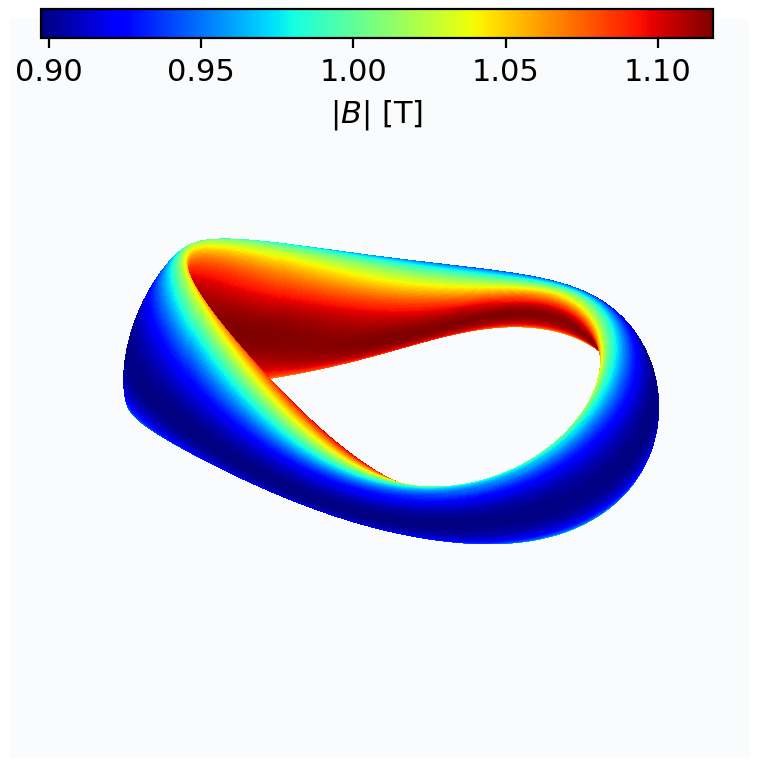

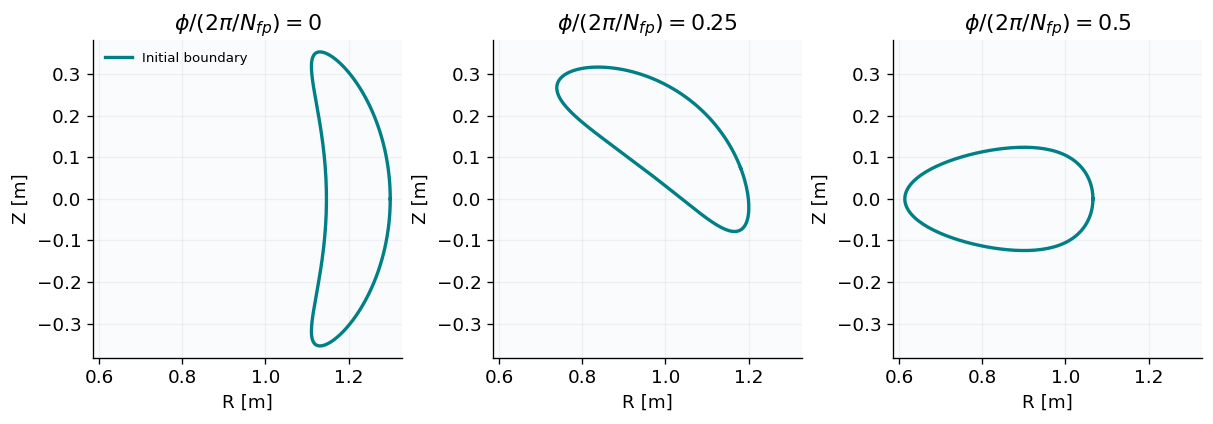

In [6]:
display(Image(filename=str(plot_boundary_3d(initial.wout, OUTPUT / "boundary.png")), width=620))
show_sections([initial], ["Initial boundary"])

**Try one degree of freedom.** Choose a coefficient below and move it by one normalized unit. The dashed boundary differs by only 3 mm in one Fourier coefficient; the field inside is re-solved. The full optimizer will vary all six together.

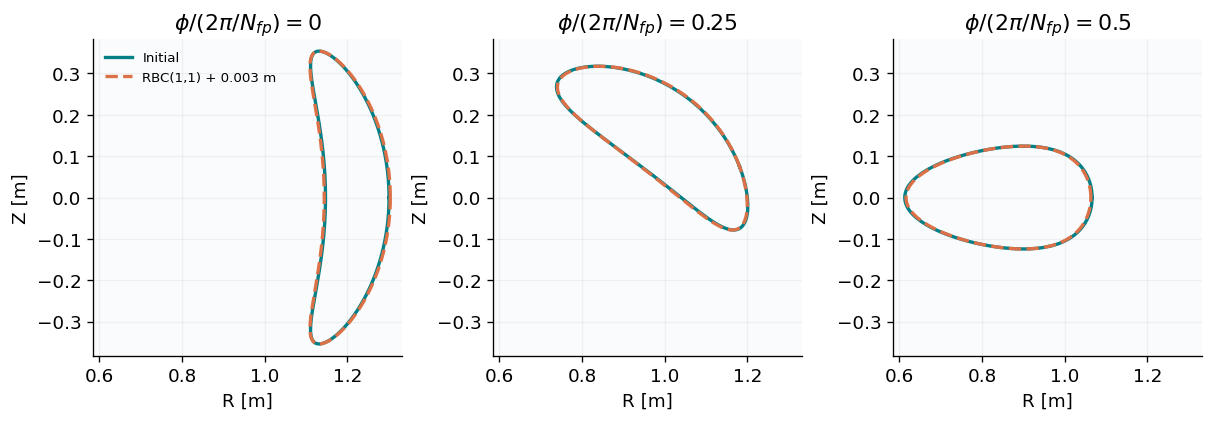

In [7]:
MODE = 4                         # RBC(1,1); choose 0 through 5
AMPLITUDE = 1.0                  # normalized units
x_trial = np.zeros(len(DOF_NAMES))
x_trial[MODE] = AMPLITUDE
trial = solve(x_trial)
show_sections([initial, trial], ["Initial", f"{DOF_NAMES[MODE]} + {STEP*AMPLITUDE:g} m"])

## What comes back from the solver?

The input vector describes a boundary; the output vector describes a magnetic configuration. Keep the physical labels separate from the loss used to select a design.

| Output | Meaning | How to use it |
|---|---|---|
| Mean iota, $\bar\iota$ | Mean poloidal winding per toroidal turn; signed arithmetic mean on the half radial mesh | Match a target; a mean alone does not prevent low-iota surfaces |
| Aspect ratio, $A$ | Major radius divided by effective minor radius | Keep a desired compactness |
| Quasisymmetry (QS) residual | Departure from a symmetry of field strength in Boozer magnetic coordinates; here quasi-axisymmetry | Smaller is better for this symmetry target |
| Constructed QI residual | Departure from a constructed quasi-isodynamic field, with poloidally closed strength contours and vanishing orbit-averaged radial drift in the ideal limit | Alternative confinement objective to QS |
| $\Gamma_c$ | Bounce-averaged fast-particle drift-alignment proxy | Smaller is favorable; it is not a lost-particle fraction |
| Mapped pwO residual | Field-strength variation across a specified piecewise-omnigenous construction | A construction proxy; a small residual does not certify piecewise omnigenity or confinement |
| $\epsilon_{\rm eff}^{3/2}$ | Effective-ripple measure entering neoclassical transport in the $1/\nu$ regime | Report the exponent; it is not total plasma transport |
| Magnetic well | $(V'(0)-V'(1))/V'(0)$, with $V'=dV/ds$ and $V$ the enclosed volume | Positive is favorable; this is not a finite-pressure stability certificate |

Boozer angles differ from the boundary angles above; QS is a symmetry of field strength, not of the geometric surface. Here $s$ is toroidal flux divided by its boundary value, from 0 on axis to 1 at the boundary. Surface selection, spatial resolution, and diagnostic quadrature are part of a label's definition. The database script exposes all eight quantities; expensive diagnostics are opt-in. Failed solves and unavailable labels are retained as missing values with error information.

QS, QI, and pwO describe different design strategies. We do not minimize every row at once. The default teaching loss is simply

$$
L=\frac12\left(\frac{\bar\iota-0.45}{0.05}\right)^2+
\frac12\left(\frac{A-6}{0.5}\right)^2.
$$

This loss does not penalize QS or magnetic well; improving it can worsen confinement-related metrics. The denominators express preferences, not measurement uncertainty. Changing them changes the design problem.

## 1. Learn from a database

The companion `database_optimization.py` exposes all eight labels and saves a reusable archive. Here we use four inexpensive labels and a small radial-basis surrogate to keep the workflow visible. Every configuration is solved independently. Failed samples remain NaN, with their reason recorded; they never become training labels.

In [8]:
X = np.vstack([np.zeros(len(DOF_NAMES)),
               2*qmc.Sobol(len(DOF_NAMES), scramble=True, seed=RANDOM_SEED).random_base2(SOBOL_POWER)-1])
Y, errors = np.full((len(X), 4), np.nan), [""]*len(X)
for i, x in enumerate(X):
    try:
        eq = solve(x)
        Y[i] = np.asarray(physical_labels(eq.state, eq.runtime))
    except (vj.VmecError, RuntimeError, ValueError) as error:
        errors[i] = str(error)
    if (i+1) % 16 == 0 or i+1 == len(X):
        print(f"Evaluated {i+1}/{len(X)} boundaries")
valid = np.isfinite(Y).all(axis=1)
print(f"Usable samples: {valid.sum()}/{len(X)}")

Evaluated 16/65 boundaries


Evaluated 32/65 boundaries


Evaluated 48/65 boundaries


Evaluated 64/65 boundaries


Evaluated 65/65 boundaries
Usable samples: 65/65


Keep the test rows out of training and normalization. This split measures interpolation near one seed. A larger study should also hold out whole stellarator families or optimization trajectories. The surrogate below is a baseline to replace, not a proposed best model.

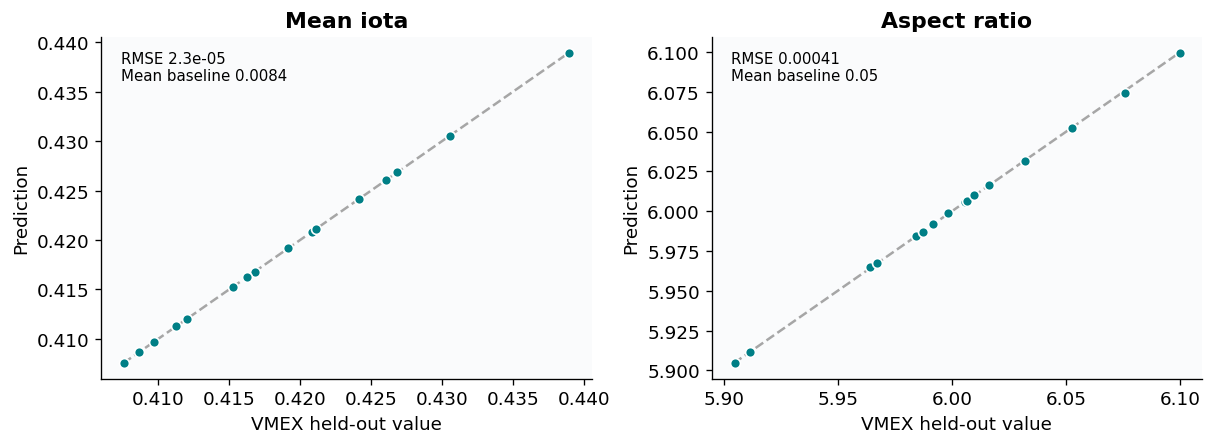

In [9]:
test = np.zeros(len(X), dtype=bool)
test[1+np.random.default_rng(RANDOM_SEED).permutation(len(X)-1)[:len(X)//4]] = True
train = valid & ~test
test &= valid
center, scale = Y[train].mean(axis=0), Y[train].std(axis=0)
scale = np.maximum(scale, 1e-12)
surrogate = RBFInterpolator(X[train], (Y[train]-center)/scale, smoothing=1e-6)
prediction = center+scale*surrogate(X[test])
show_predictions(Y[test], prediction, center)

Ask the surrogate for a promising boundary, then evaluate it with VMEX. Model accuracy on held-out rows does not guarantee accuracy at the point chosen by an optimizer. Keep the seed if the verified proposal is worse.

In [10]:
def score(labels):
    """Apply the same target loss to predicted or independently solved labels."""
    return 0.5*np.sum(((np.asarray(labels)[..., :2]-TARGETS)/SCALES)**2, axis=-1)


candidates = 2*qmc.Sobol(len(DOF_NAMES), scramble=True, seed=RANDOM_SEED+1).random_base2(12)-1
proposed_x = candidates[np.argmin(score(center+scale*surrogate(candidates)))]
proposal = solve(proposed_x)
proposal_y = np.asarray(physical_labels(proposal.state, proposal.runtime))
print(f"True loss: {score(Y[0]):.6f} → {score(proposal_y):.6f}")
selected_x = proposed_x if score(proposal_y) < score(Y[0]) else np.zeros(len(DOF_NAMES))

True loss: 0.189801 → 0.034518


The four label columns are `mean_iota`, `aspect_ratio`, `qs_qa_total`, and `magnetic_well`. The scripts in the PR add provenance and optional QI, Gamma_c, pwO and effective-ripple calculations. Their resolutions are explicit; those more expensive diagnostics are not needed for this first training loop.

In [11]:
np.savez(OUTPUT / "local_database.npz", X=X, Y=Y, valid=valid, errors=errors,
         train=train, test=test, label_names=LABEL_NAMES, dof_names=DOF_NAMES, step=STEP, targets=TARGETS, scales=SCALES)
print("Saved the local database. X contains normalized shape inputs; Y contains physical labels.")

Saved the local database. X contains normalized shape inputs; Y contains physical labels.


## 2. Differentiate through the physics

Now use VMEX derivatives for the same six parameters and target loss. The companion `differentiable_optimization.py` also records timings and metadata. The core interface is ordinary JAX and Optax:

```python
value, gradient = jax.value_and_grad(loss)(x)
updates, optimizer_state = optimizer.update(gradient, optimizer_state, x)
x = jnp.clip(optax.apply_updates(x, updates), -1, 1)
```

The learned variables here are the shape coefficients themselves. There is no neural network to train. You can also put a network upstream of this loss, or use these gradients as labels for a surrogate.

If $u$ denotes the equilibrium state and $F(u,x)=0$ its discrete equations, the derivative follows from

$$
F_u\,du/dx=-F_x.
$$

For a scalar loss, an adjoint solve computes the gradient without storing the forward iteration history. The first call includes JAX compilation; later calls reuse it. This is a derivative of the discretized equilibrium, conditional on convergence and a well-defined local branch. Automatic differentiation does not remove spatial or quadrature error.

Below we check a directional derivative with independent solves, run Adam, then independently solve the initial and best boundaries at the original and a finer radial grid. The companion script checks three finite-difference step sizes. The angular resolution is unchanged; this is a partial refinement check. Adam is used because its interface is familiar, not because it is the best optimizer for six parameters. L-BFGS-B and least-squares methods are useful comparisons.

In [12]:
def loss(x):
    """Normalized parameters → VMEX equilibrium → scalar loss."""
    return problem.jax_fun(x_seed+STEP*x)


value_and_grad = jax.value_and_grad(loss)
x = jnp.zeros(len(DOF_NAMES))
value, gradient = value_and_grad(x)
print(f"Initial loss: {float(value):.6f}")

Initial loss: 0.189657


Before training, compare the derivative with independently converged positive and negative perturbations. This is a local check of the discrete derivative. Smaller steps eventually reveal solver tolerance error; larger steps introduce finite-difference truncation error.

In [13]:
direction = np.asarray(gradient)/np.linalg.norm(gradient)
h = 0.01
plus, minus = solve(h*direction), solve(-h*direction)
fd = (float(physical_loss(plus.state, plus.runtime))
      - float(physical_loss(minus.state, minus.runtime)))/(2*h)
ad = float(gradient @ direction)
print(f"Directional derivative: AD {ad:.7f}; FD {fd:.7f}; relative error {abs(ad/fd-1):.2g}")
np.testing.assert_allclose(ad, fd, rtol=1e-3, atol=1e-6)

Directional derivative: AD 0.1698243; FD 0.1698824; relative error 0.00034


In [14]:
optimizer = optax.chain(optax.clip_by_global_norm(1.0), optax.adam(LEARNING_RATE))
optimizer_state = optimizer.init(x)
xs, losses = [], []
for iteration in range(ADAM_STEPS+1):
    value, gradient = value_and_grad(x)
    if not np.isfinite(value) or not np.isfinite(gradient).all():
        raise RuntimeError("Non-finite loss/gradient; inspect the equilibrium before continuing")
    xs.append(np.asarray(x)); losses.append(float(value))
    if iteration < ADAM_STEPS:
        updates, optimizer_state = optimizer.update(gradient, optimizer_state, x)
        x = jnp.clip(optax.apply_updates(x, updates), -1, 1)
best_x = xs[int(np.argmin(losses))]

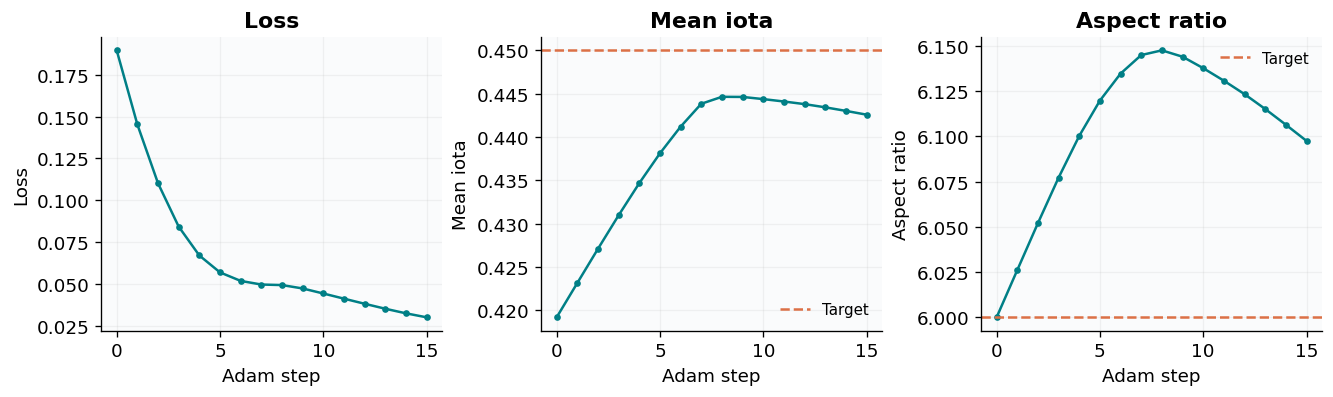

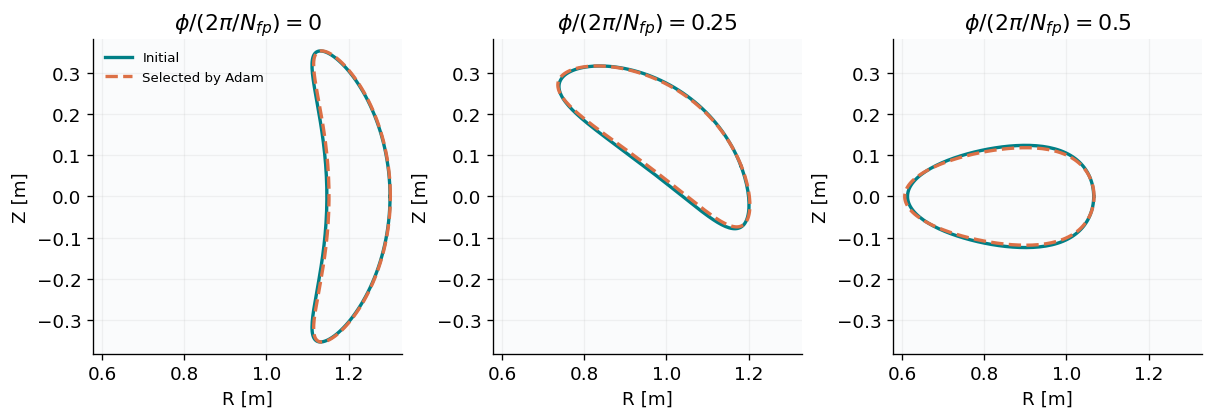

In [15]:
# These physical labels come from independent solves, not the surrogate.
trajectory = [solve(x) for x in xs]
values = np.array([physical_labels(eq.state, eq.runtime) for eq in trajectory])
show_training(losses, values)
show_sections([initial, trajectory[int(np.argmin(losses))]], ["Initial", "Selected by Adam"])

Adam need not improve every step. We keep its best evaluated point and check both endpoints on a finer radial grid. Angular resolution is unchanged here; increase it too before interpreting a small gain as a physical improvement. The two routes have different evaluation budgets, so these results are not an optimizer ranking.

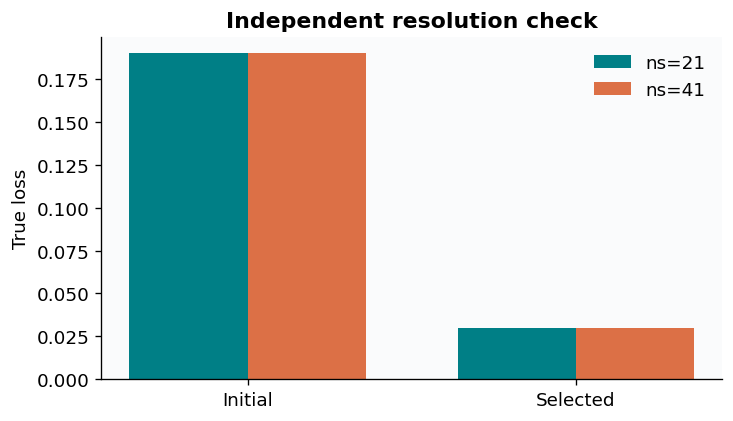

Independently solved losses: [0.18980140606440918, 0.030048632093594818]
Refined-grid losses: [0.18972597325216528, 0.03003011847202837]


In [16]:
coarse, refined = [], []
for x in (np.zeros(len(DOF_NAMES)), best_x):
    for ns, results in ((NS, coarse), (2*NS-1, refined)):
        eq = solve(x, ns=ns)
        results.append(float(physical_loss(eq.state, eq.runtime)))
show_verification(coarse, refined)
print("Independently solved losses:", coarse)
print("Refined-grid losses:", refined)

## Experiments worth trying

1. **Change the optimizer.** Keep the starting point, parameter bounds, loss, and evaluation budget fixed. Compare Adam with L-BFGS-B, a derivative-free method, or your optimizer. Report wall time, first-call compilation, physics evaluations, and independently verified final loss.
2. **Change the learner.** Replace the database response surface with a small network or ensemble. Compare against the existing baseline before adding capacity. Query VMEX where uncertainty is high or a candidate looks promising, then retrain.
3. **Change the physics objective.** Add a QA residual or a magnetic-well floor. For a floor, penalize only violations. QI and pwO are alternative design directions; a weighted sum of every available metric has no automatic physical justification.
4. **Try a larger design space.** Add Fourier coefficients gradually and reduce their allowed amplitude at higher mode number. Hold out whole starting configurations when measuring generalization. Fix scale and angle conventions before mixing databases.
5. **Check what the optimizer found.** Increase equilibrium and diagnostic resolution, repeat the gradient check over several perturbation sizes, inspect the iota profile, and evaluate confinement independently. A better coarse-grid loss can disappear on a finer grid.

The default examples do not optimize coils, island formation, finite-pressure stability, turbulence, or engineering limits. VMEX assumes nested flux surfaces. Treat these results as small numerical experiments, then add the physics needed for your research question.

## Data and code for larger studies

- [ConStellaration](https://arxiv.org/abs/2506.19583): QI-like boundary data and constrained optimization benchmarks, with [reference code](https://github.com/proximafusion/constellaration) and a [dataset](https://huggingface.co/datasets/proxima-fusion/constellaration). Preserve the release, coordinate conventions, pressure/current settings, and label definitions when comparing results.
- [QUASR](https://quasr.flatironinstitute.org/): quasisymmetric configurations and associated coils, useful when moving from boundary design to coil geometry.
- [BoSS](https://arxiv.org/abs/2610.37910): a 2026 preprint and [fast-ion simulation dataset](https://boss.flatironinstitute.org/), for questions that require particle information beyond equilibrium proxies.
- [DESC](https://github.com/PlasmaControl/DESC) and [SIMSOPT](https://github.com/hiddenSymmetries/simsopt): alternative equilibrium and optimization tools. Their data and objective normalizations are not interchangeable by name alone.

## A short reading path

- [Landreman & Paul (2022)](https://doi.org/10.1103/PhysRevLett.128.035001): the quasi-axisymmetric seed and why magnetic symmetry matters.
- [VMEX objective definitions](https://vmex.readthedocs.io/en/latest/reference/objectives.html): the quantities used by the scripts, including conventions and limitations.
- [VMEX adjoint gradients](https://vmex.readthedocs.io/en/latest/explanation/adjoint-gradients.html): what the implicit derivative represents and how to check it.
- [Goodman et al. (2023)](https://arxiv.org/abs/2211.09829): constructing nearly quasi-isodynamic fields.
- [Velasco et al. (2024)](https://arxiv.org/abs/2405.07634): the definition of piecewise omnigenity; [Liu et al. (2026)](https://arxiv.org/abs/2603.12139) describes the mapped construction used here.
- [Velasco et al. (2021)](https://arxiv.org/abs/2106.05697): fast-ion proxies and their relationship to prompt losses; [Nemov et al. (1999)](https://doi.org/10.1063/1.873749) defines effective ripple.
- [Merlo et al.](https://arxiv.org/abs/2211.09743): a physics-regularized equilibrium surrogate. The ConStellaration paper above provides an ML benchmark.

Start by changing one target or replacing one optimizer, then check the result with VMEX.